In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
DATA_SOURCE = "https://raw.githubusercontent.com/akmand/datasets/main/california_housing.csv"
RANDOM_STATE = 42

df = pd.read_csv(DATA_SOURCE)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [3]:
print("The shape of the dataset is (rows, columns):", df.shape)

print("The first 5 rows are: ")
print(df.head())

print("The column names:")
print(df.columns.tolist())

print("Information about the dataset with some standard details:")
df.info()

The shape of the dataset is (rows, columns): (20640, 10)
The first 5 rows are: 
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                  41          880           129.0   
1    -122.22     37.86                  21         7099          1106.0   
2    -122.24     37.85                  52         1467           190.0   
3    -122.25     37.85                  52         1274           235.0   
4    -122.25     37.85                  52         1627           280.0   

   population  households  median_income ocean_proximity  median_house_value  
0         322         126         8.3252        NEAR BAY              452600  
1        2401        1138         8.3014        NEAR BAY              358500  
2         496         177         7.2574        NEAR BAY              352100  
3         558         219         5.6431        NEAR BAY              341300  
4         565         259         3.8462        NEAR BAY              3422

In [4]:
display(df.describe())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [5]:
print("No. of null values per column: ")
display(df.isnull().sum().sort_values(ascending=False))


print("No. of duplicated rows: ", df.duplicated().sum())

No. of null values per column: 


total_bedrooms        207
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
population              0
households              0
median_income           0
ocean_proximity         0
median_house_value      0
dtype: int64

No. of duplicated rows:  0


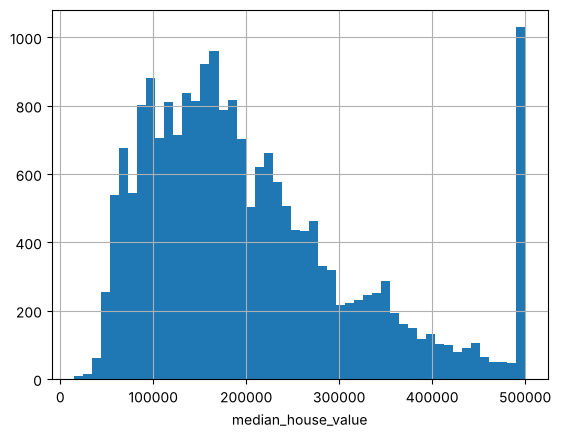

No. of rows at the max value (capped): 965


In [6]:
import matplotlib.pyplot as plt

df["median_house_value"].hist(bins=50)
plt.xlabel("median_house_value")
plt.show()

print("No. of rows at the max value (capped):", (df["median_house_value"] == df["median_house_value"].max()).sum())

In [7]:
df = pd.get_dummies(df, columns=["ocean_proximity"], drop_first=True)

print("The shape after encoding:", df.shape)

The shape after encoding: (20640, 13)


In [8]:
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)

print("Training set shape: ", X_train.shape)
print("Testing set shape: ", X_test.shape)

Training set shape:  (16512, 12)
Testing set shape:  (4128, 12)


In [9]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


In [10]:
med = X_train["total_bedrooms"].median()

X_train["total_bedrooms"] = X_train["total_bedrooms"].fillna(med)

X_test["total_bedrooms"] = X_test["total_bedrooms"].fillna(med)

print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

0 0


In [11]:
from sklearn.preprocessing import StandardScaler

In [12]:
scaler = StandardScaler()
numeric_cols = X_train.select_dtypes(include=[np.number]).columns
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [14]:
lir = LinearRegression()
lir.fit(X_train_scaled, y_train)
lir_pred = lir.predict(X_test_scaled)

print("root mean squared error:", np.sqrt(mean_squared_error(y_test, lir_pred)))
print("mae:", mean_absolute_error(y_test, lir_pred))
print("r2 score:", r2_score(y_test, lir_pred))

root mean squared error: 70059.19333925015
mae: 50670.48923565359
r2 score: 0.6254382675296265


In [15]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.1, random_state=42)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

print("root mean squared error:", np.sqrt(mean_squared_error(y_test, xgb_pred)))
print("mean absolute error:", mean_absolute_error(y_test, xgb_pred))
print("r2 score:", r2_score(y_test, xgb_pred))

root mean squared error: 47402.22982096939
mean absolute error: 31435.197265625
r2 score: 0.8285290002822876


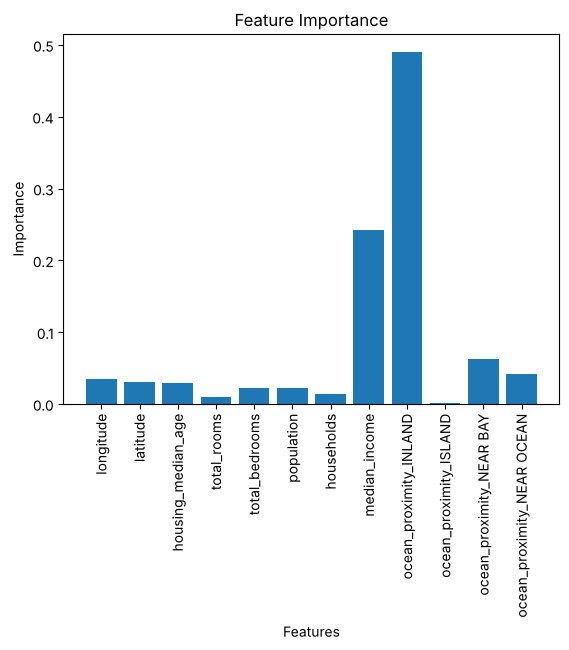

In [16]:
plt.bar(X_train.columns, xgb.feature_importances_)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance")
plt.xticks(rotation=90)
plt.show()

In [17]:
lr_rmse = np.sqrt(mean_squared_error(y_test, lir_pred))
lr_mae = mean_absolute_error(y_test, lir_pred)
lr_r2 = r2_score(y_test, lir_pred)

xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_r2 = r2_score(y_test, xgb_pred)

In [18]:
metrics_df = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2 Score"],
    "Linear Regression": [lr_rmse, lr_mae, lr_r2],
    "XGBoost": [xgb_rmse, xgb_mae, xgb_r2]
})

display(metrics_df.round(4))

,Metric,Linear Regression,XGBoost
0,RMSE,70059.1933,47402.2298
1,MAE,50670.4892,31435.1973
2,R2 Score,0.6254,0.8285


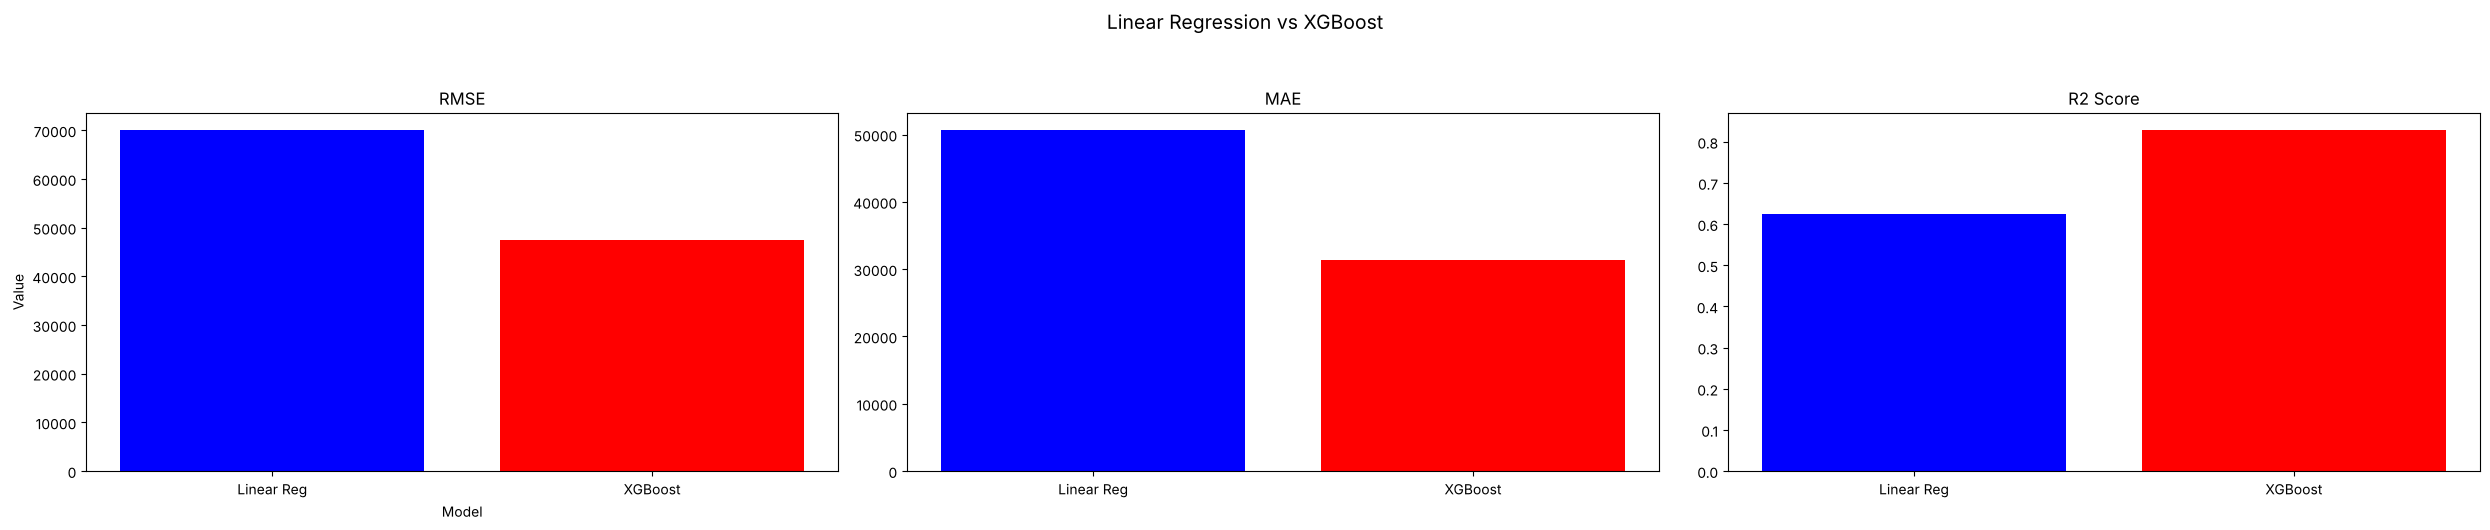

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(25, 5))

axes[0].bar(["Linear Reg", "XGBoost"], [lr_rmse, xgb_rmse], color=['blue', 'red'])
axes[0].set_title("RMSE")
axes[0].set_ylabel("Value")
axes[0].set_xlabel("Model")

axes[1].bar(["Linear Reg", "XGBoost"], [lr_mae, xgb_mae], color=['blue', 'red'])
axes[1].set_title("MAE")

axes[2].bar(["Linear Reg", "XGBoost"], [lr_r2, xgb_r2], color=['blue', 'red'])
axes[2].set_title("R2 Score")

plt.suptitle("Linear Regression vs XGBoost", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

In [20]:
#xgboost gave us much superior results here.

In [21]:
import joblib

joblib.dump(xgb, "california_model.pkl")

print("MODEL SAVED!!!")

MODEL SAVED!!!


In [22]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

lir_cv = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), X_train, y_train, cv=5, scoring="r2")
xgb_cv = cross_val_score(XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.1, random_state=42), X_train, y_train, cv=5, scoring="r2")

print("linear regression cv r2 scores:", lir_cv.round(3), "mean:", lir_cv.mean().round(3))
print("xgboost cv r2 scores:", xgb_cv.round(3), "mean:", xgb_cv.mean().round(3))

linear regression cv r2 scores: [0.655 0.649 0.66  0.647 0.627] mean: 0.648
xgboost cv r2 scores: [0.838 0.831 0.836 0.833 0.827] mean: 0.833


In [23]:
def add_features(d):
    d = d.copy()
    d["rooms_per_household"] = d["total_rooms"] / d["households"]
    d["bedrooms_per_room"] = d["total_bedrooms"] / d["total_rooms"]
    d["people_per_household"] = d["population"] / d["households"]
    return d

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

xgb_fe = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.1, random_state=42)
xgb_fe.fit(X_train_fe, y_train)
fe_pred = xgb_fe.predict(X_test_fe)

print("rmse before new features:", np.sqrt(mean_squared_error(y_test, xgb_pred)))
print("rmse after new features:", np.sqrt(mean_squared_error(y_test, fe_pred)))
print("r2 before new features:", r2_score(y_test, xgb_pred))
print("r2 after new features:", r2_score(y_test, fe_pred))

rmse before new features: 47402.22982096939
rmse after new features: 45751.578246001525
r2 before new features: 0.8285290002822876
r2 after new features: 0.8402630686759949


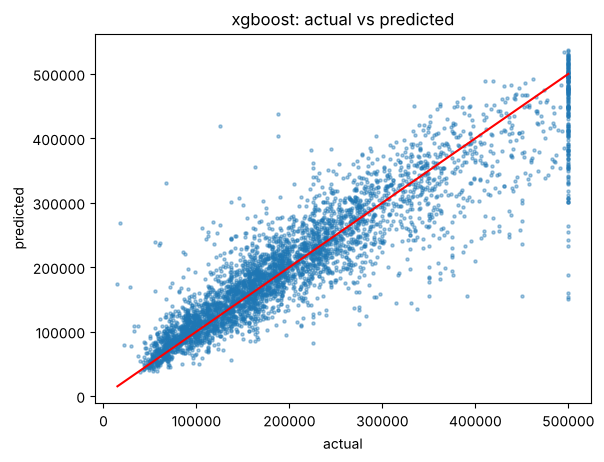

In [24]:
plt.scatter(y_test, xgb_pred, s=5, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("actual")
plt.ylabel("predicted")
plt.title("xgboost: actual vs predicted")
plt.show()